In [7]:
# Unemployment Analysis in India

## Project Overview

This project analyses unemployment trends across Indian states and
regions, with particular attention to the impact of COVID-19.

The analysis explores:
- State-wise average unemployment rates.
- Monthly unemployment trends.
- Rural and urban unemployment patterns.
- Labour participation and employment indicators.
- Changes in unemployment before and during the COVID-19 period.

## Datasets

1. Unemployment in India.csv
2. Unemployment_Rate_upto_11_2020.csv

The datasets are analysed separately because their structures and
aggregation levels differ.

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

SyntaxError: invalid syntax (2174156967.py, line 5)

In [8]:
from pathlib import Path
print(Path.cwd())

/home/kumar/DIRECTORIES/OIBSIP/DataScience-Task2-UnemploymentAnalysis/notebooks


In [9]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [10]:
from pathlib import Path

DATASET_DIR = Path("../dataset")
# Load Dataset A
df_rural_urban = pd.read_csv(
    DATASET_DIR / "Unemployment in India.csv",
    encoding="utf-8-sig"
)

# Load Dataset B
df_state = pd.read_csv(
    DATASET_DIR / "Unemployment_Rate_upto_11_2020.csv",
    encoding="utf-8-sig"
)

# Standardize column names
df_rural_urban.columns = df_rural_urban.columns.str.strip()
df_state.columns = df_state.columns.str.strip()

print("Dataset A:", df_rural_urban.shape)
print("Dataset B:", df_state.shape)

Dataset A: (768, 7)
Dataset B: (267, 9)


In [11]:
print("DATASET A — RURAL AND URBAN")
display(df_rural_urban.head())

print("\nDATASET B — STATE LEVEL")
display(df_state.head())

DATASET A — RURAL AND URBAN


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.00,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.00,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.00,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.00,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.00,44.68,Rural



DATASET B — STATE LEVEL


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.91,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.91,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.91,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.91,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.91,79.74


In [12]:
## 2. Data Cleaning and Preparation

In this section, we:
- Remove completely empty rows.
- Standardize column names and text values.
- Convert date columns into datetime format.
- Convert numerical columns into appropriate data types.
- Check missing values and duplicate records.
- Validate the cleaned datasets before analysis.

SyntaxError: invalid syntax (1533859476.py, line 3)

In [13]:
# Work on a copy; preserve the original DataFrame
df_rural_clean = df_rural_urban.copy()

# Remove completely empty rows
df_rural_clean = df_rural_clean.dropna(how="all").copy()

# Clean text columns
text_columns = ["Region", "Frequency", "Area"]

for column in text_columns:
    df_rural_clean[column] = (
        df_rural_clean[column].astype("string").str.strip()
    )

# Convert Date column
df_rural_clean["Date"] = pd.to_datetime(
    df_rural_clean["Date"].astype("string").str.strip(),
    format="%d-%m-%Y",
    errors="coerce"
)

# Convert numerical columns
numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for column in numeric_columns:
    df_rural_clean[column] = pd.to_numeric(
        df_rural_clean[column], errors="coerce"
    )

print("Dataset A cleaning completed.")
print("Original shape:", df_rural_urban.shape)
print("Cleaned shape:", df_rural_clean.shape)

Dataset A cleaning completed.
Original shape: (768, 7)
Cleaned shape: (740, 7)


In [14]:
df_state_clean = df_state.copy()

# Remove completely empty rows
df_state_clean = df_state_clean.dropna(how="all").copy()

# Clean text columns
text_columns = ["Region", "Frequency", "Region.1"]

for column in text_columns:
    df_state_clean[column] = (
        df_state_clean[column].astype("string").str.strip()
    )

# Convert Date column
df_state_clean["Date"] = pd.to_datetime(
    df_state_clean["Date"].astype("string").str.strip(),
    format="%d-%m-%Y",
    errors="coerce"
)

# Convert numerical columns
numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)",
    "longitude",
    "latitude"
]

for column in numeric_columns:
    df_state_clean[column] = pd.to_numeric(
        df_state_clean[column], errors="coerce"
    )

print("Dataset B cleaning completed.")
print("Original shape:", df_state.shape)
print("Cleaned shape:", df_state_clean.shape)

Dataset B cleaning completed.
Original shape: (267, 9)
Cleaned shape: (267, 9)


In [15]:
print("Dataset A:", df_rural_clean.shape)
print("Dataset B:", df_state_clean.shape)

print("\nDataset A missing values:")
print(df_rural_clean.isnull().sum())

print("\nDataset B missing values:")
print(df_state_clean.isnull().sum())

Dataset A: (740, 7)
Dataset B: (267, 9)

Dataset A missing values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

Dataset B missing values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64


In [16]:
## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the distribution,
patterns and relationships within the unemployment dataset.

In this section, we analyse descriptive statistics, overall
unemployment levels and state-wise unemployment averages.

SyntaxError: invalid syntax (469445329.py, line 3)

In [17]:
unemployment_col = "Estimated Unemployment Rate (%)"

print("DATASET A — DESCRIPTIVE STATISTICS")
display(df_rural_clean.describe())

print("\nDATASET B — DESCRIPTIVE STATISTICS")
display(df_state_clean.describe())

DATASET A — DESCRIPTIVE STATISTICS


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.00,740.00,740.00
mean,2019-12-12 18:36:58.378378,11.79,7204460.03,42.63
min,2019-05-31 00:00:00,0.00,49420.00,13.33
25%,2019-08-31 00:00:00,4.66,1190404.50,38.06
50%,2019-11-30 00:00:00,8.35,4744178.50,41.16
75%,2020-03-31 00:00:00,15.89,11275489.50,45.51
max,2020-06-30 00:00:00,76.74,45777509.00,72.57
std,NaN,10.72,8087988.43,8.11



DATASET B — DESCRIPTIVE STATISTICS


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),longitude,latitude
count,267,267.00,267.00,267.00,267.00,267.00
mean,2020-06-16 09:15:30.337078,12.24,13962105.72,41.68,22.83,80.53
min,2020-01-31 00:00:00,0.50,117542.00,16.77,10.85,71.19
25%,2020-03-31 00:00:00,4.84,2838930.50,37.27,18.11,76.09
50%,2020-06-30 00:00:00,9.65,9732417.00,40.39,23.61,79.02
75%,2020-08-31 00:00:00,16.75,21878686.00,44.05,27.28,85.28
max,2020-10-31 00:00:00,75.85,59433759.00,69.69,33.78,92.94
std,NaN,10.80,13366318.36,7.85,6.27,5.83


In [18]:
print("DATASET B — OVERALL UNEMPLOYMENT SUMMARY")

overall_average = df_state_clean[unemployment_col].mean()
overall_median = df_state_clean[unemployment_col].median()
highest_rate = df_state_clean[unemployment_col].max()
lowest_rate = df_state_clean[unemployment_col].min()

print(f"Average unemployment rate: {overall_average:.2f}%")
print(f"Median unemployment rate: {overall_median:.2f}%")
print(f"Highest recorded rate: {highest_rate:.2f}%")
print(f"Lowest recorded rate: {lowest_rate:.2f}%")

DATASET B — OVERALL UNEMPLOYMENT SUMMARY
Average unemployment rate: 12.24%
Median unemployment rate: 9.65%
Highest recorded rate: 75.85%
Lowest recorded rate: 0.50%


In [19]:
state_unemployment = (
    df_state_clean.groupby("Region")[unemployment_col]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

state_unemployment.columns = [
    "Region",
    "Average Unemployment Rate (%)"
]

display(state_unemployment.round(2))

,Region,Average Unemployment Rate (%)
0,Haryana,27.48
1,Tripura,25.06
2,Jharkhand,19.54
3,Bihar,19.47
4,Delhi,18.41
5,Puducherry,17.94
6,Jammu & Kashmir,16.48
7,Himachal Pradesh,16.07
8,Rajasthan,15.87
9,Tamil Nadu,12.19


In [20]:
### Initial Observations

The descriptive statistics provide an overview of unemployment
across the available Indian state-level observations.

The state-wise averages help identify regional differences
in unemployment.

These averages are calculated from available observations in
Dataset B. They should not be interpreted as official
population-weighted national unemployment rates.

SyntaxError: invalid syntax (2758297590.py, line 3)

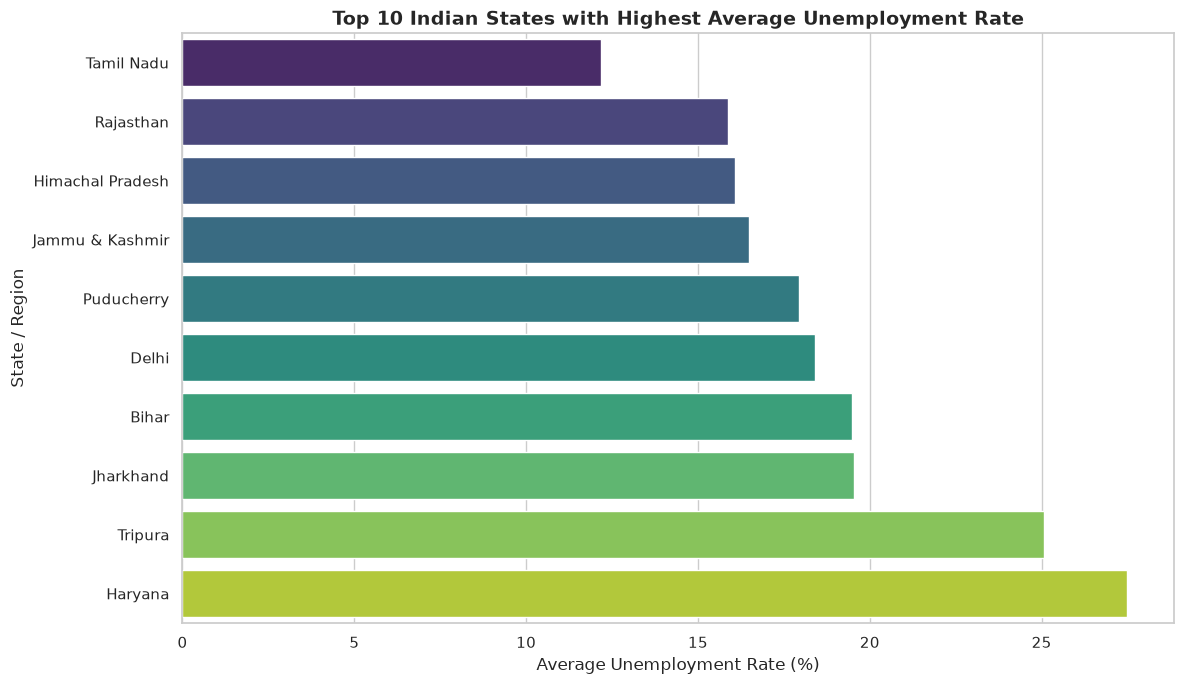

In [21]:
# Select the top 10 states
top_10_states = state_unemployment.head(10).copy()

# Reverse order so the highest value appears at the top
top_10_states = top_10_states.sort_values(
    by="Average Unemployment Rate (%)",
    ascending=True
)

# Create bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_states,
    x="Average Unemployment Rate (%)",
    y="Region",
    hue="Region",
    palette="viridis",
    legend=False
)

plt.title(
    "Top 10 Indian States with Highest Average Unemployment Rate",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State / Region")
plt.tight_layout()

# Save chart
plt.savefig(
    "../screenshots/top_10_unemployment_states.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
### Observations — Top 10 States

The bar chart highlights the ten states with the highest
average unemployment rates in Dataset B.

Haryana and Tripura appear among the states with the highest
average unemployment rates, followed by Jharkhand and Bihar.

These rankings represent averages of the available observations
in the dataset. Differences in observation coverage should be
considered when interpreting the results.

SyntaxError: invalid syntax (1745650504.py, line 3)

In [23]:
## 4. Monthly Unemployment Trend Analysis

This section analyses how the average unemployment rate
changed across months during 2020.

The monthly averages are calculated across available
state-level observations in Dataset B.

SyntaxError: invalid syntax (2804061844.py, line 3)

/tmp/ipykernel_32249/4011715694.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_unemployment.round(2))


,Date,Estimated Unemployment Rate (%)
0,2020-01-31,9.20
1,2020-02-29,9.27
2,2020-03-31,10.78
3,2020-04-30,22.24
4,2020-05-31,23.24
5,2020-06-30,10.91
6,2020-07-31,9.83
7,2020-08-31,10.31
8,2020-09-30,8.71
9,2020-10-31,8.03


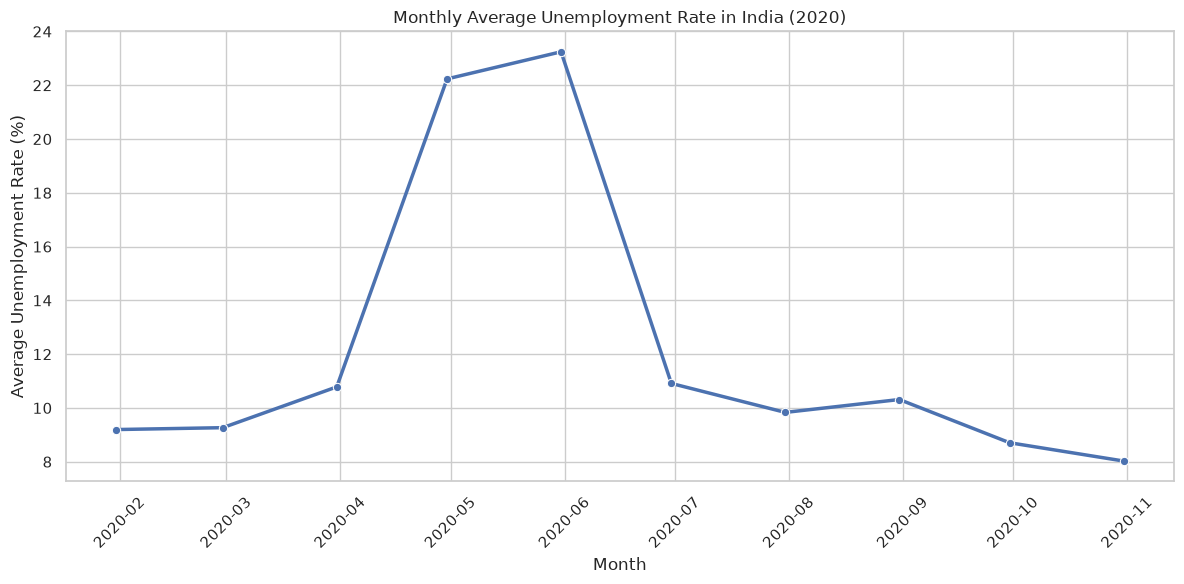

In [24]:
# Calculate monthly average unemployment rate
monthly_unemployment = (
    df_state_clean.groupby("Date")[unemployment_col]
    .mean()
    .reset_index()
)

monthly_unemployment = monthly_unemployment.sort_values("Date")

display(monthly_unemployment.round(2))

# Plot monthly unemployment trend
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_unemployment,
    x="Date",
    y=unemployment_col,
    marker="o",
    linewidth=2.5
)

plt.title("Monthly Average Unemployment Rate in India (2020)")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../screenshots/monthly_unemployment_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
## 5. State-wise Unemployment Trend Comparison

This section compares monthly unemployment rates across
three selected Indian states: Maharashtra, Tamil Nadu and Haryana.

The comparison helps us understand how unemployment trends
differed across states during 2020.

SyntaxError: invalid syntax (2846756079.py, line 3)

,Date,Region,Estimated Unemployment Rate (%)
70,2020-01-31,Haryana,20.34
207,2020-01-31,Tamil Nadu,1.57
139,2020-01-31,Maharashtra,4.95
71,2020-02-29,Haryana,25.77
208,2020-02-29,Tamil Nadu,2.09
140,2020-02-29,Maharashtra,4.69
72,2020-03-31,Haryana,25.05
209,2020-03-31,Tamil Nadu,6.40
141,2020-03-31,Maharashtra,5.79
73,2020-04-30,Haryana,43.22


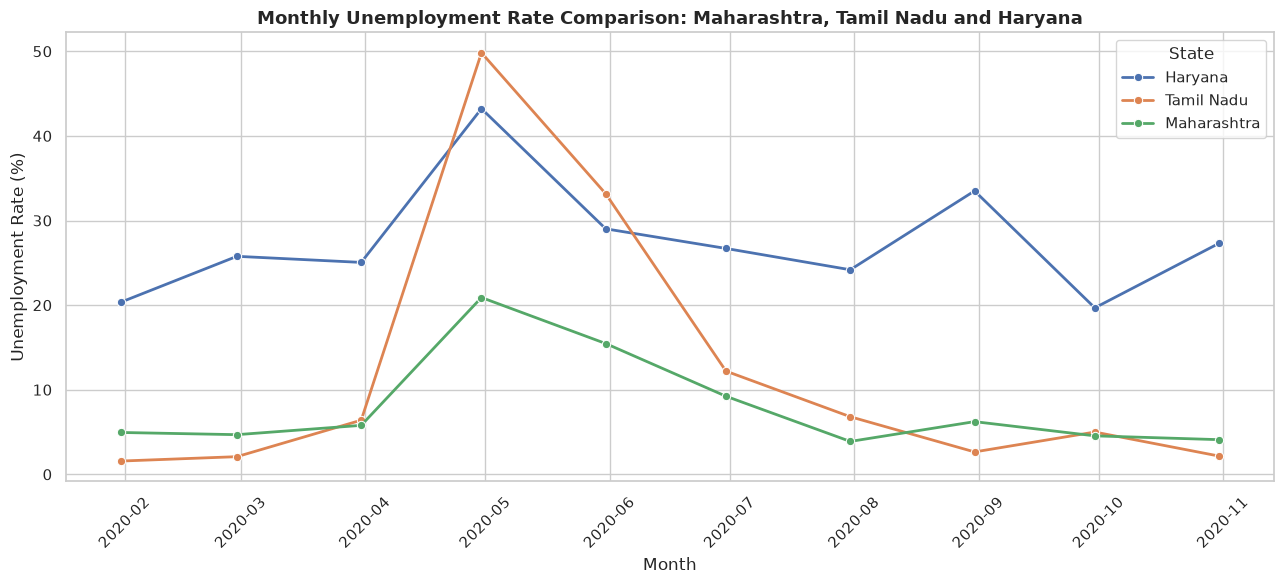

In [26]:
# Select three states for comparison
selected_states = ["Maharashtra", "Tamil Nadu", "Haryana"]

# Filter records for selected states
state_trends = df_state_clean[
    df_state_clean["Region"].isin(selected_states)
].copy()

# Sort data chronologically
state_trends = state_trends.sort_values("Date")

# Display selected state data
display(
    state_trends[
        ["Date", "Region", unemployment_col]
    ].head(15)
)

# Create state-wise time-series line chart
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=state_trends,
    x="Date",
    y=unemployment_col,
    hue="Region",
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Unemployment Rate Comparison: Maharashtra, Tamil Nadu and Haryana",
    fontsize=13,
    fontweight="bold"
)
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="State")
plt.tight_layout()

plt.savefig(
    "../screenshots/statewise_unemployment_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
### Observations — State-wise Trends

The line chart compares unemployment trends across
Maharashtra, Tamil Nadu and Haryana.

The unemployment rates vary across states and months.
The COVID-19 period, particularly April and May 2020,
shows notable changes in unemployment levels.

The differences highlight that unemployment did not
affect every state in the same way.

SyntaxError: invalid syntax (2441598336.py, line 3)

In [28]:
## 6. Correlation Analysis

Correlation analysis helps us understand the relationships
between the following variables:

- Estimated Unemployment Rate
- Estimated Employed
- Estimated Labour Participation Rate

A correlation heatmap is used to visualize these relationships.

SyntaxError: invalid syntax (3131648155.py, line 3)

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.00,-0.24,-0.07
Estimated Employed,-0.24,1.00,-0.05
Estimated Labour Participation Rate (%),-0.07,-0.05,1.00


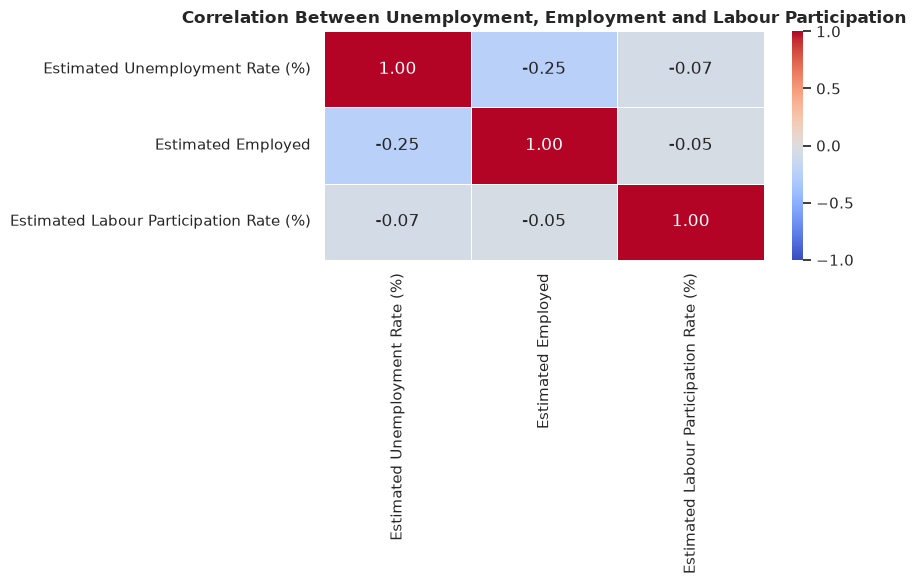

In [29]:
# Select numerical columns for correlation analysis
correlation_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

# Calculate correlation matrix
correlation_matrix = df_state_clean[
    correlation_columns
].corr()

# Display correlation values
display(correlation_matrix.round(3))

# Create correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation Between Unemployment, Employment and Labour Participation",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()

# Save chart
plt.savefig(
    "../screenshots/unemployment_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
### Observations — Correlation Heatmap

The correlation heatmap illustrates the relationships
between unemployment rate, estimated employment and
labour participation rate.

Positive correlation indicates that two variables tend
to increase together, while negative correlation indicates
that one tends to decrease as the other increases.

Correlation does not establish causation. These relationships
should be interpreted in the context of the available
state-level observations.

SyntaxError: invalid syntax (3643709453.py, line 3)

In [31]:
## 7. Pre-COVID vs COVID-Onset Unemployment Analysis

This section compares unemployment rates before the COVID-19
period and during its initial impact in India.

Pre-COVID period: May 2019 to February 2020.
COVID-onset period: March 2020 to June 2020.

Dataset A is used because it contains observations from both
periods and includes rural and urban classifications.

SyntaxError: invalid syntax (4018494792.py, line 3)

In [32]:
# Define the two periods
pre_covid = df_rural_clean[
    df_rural_clean["Date"] < "2020-03-01"
].copy()

covid_onset = df_rural_clean[
    (df_rural_clean["Date"] >= "2020-03-01") &
    (df_rural_clean["Date"] <= "2020-06-30")
].copy()

# Calculate average unemployment rates
period_comparison = pd.DataFrame({
    "Period": ["Pre-COVID", "COVID Onset"],
    "Average Unemployment Rate (%)": [
        pre_covid[unemployment_col].mean(),
        covid_onset[unemployment_col].mean()
    ]
})

display(period_comparison.round(2))

# Calculate percentage-point difference
difference = (
    period_comparison.loc[1, "Average Unemployment Rate (%)"]
    - period_comparison.loc[0, "Average Unemployment Rate (%)"]
)

print(f"Difference: {difference:.2f} percentage points")

,Period,Average Unemployment Rate (%)
0,Pre-COVID,9.51
1,COVID Onset,17.77


Difference: 8.26 percentage points


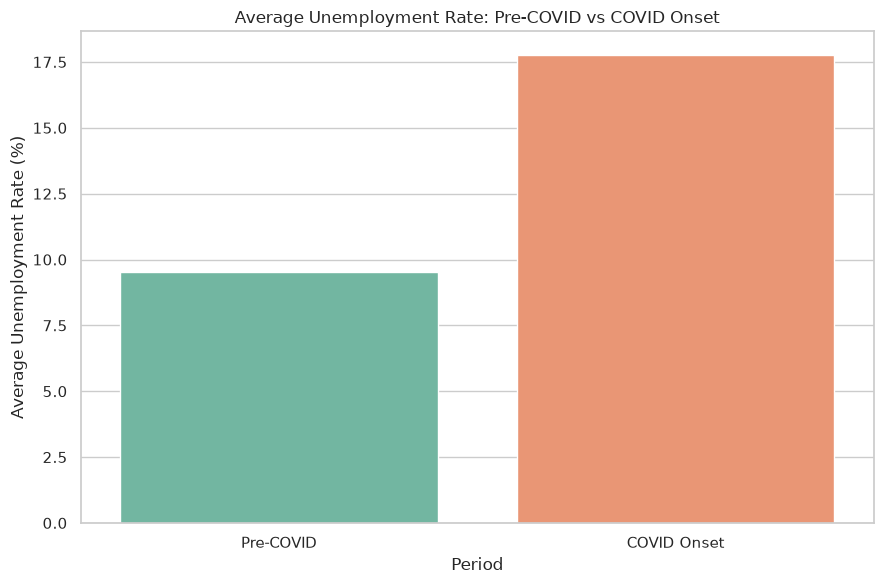

In [33]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=period_comparison,
    x="Period",
    y="Average Unemployment Rate (%)",
    hue="Period",
    palette="Set2",
    legend=False
)

plt.title("Average Unemployment Rate: Pre-COVID vs COVID Onset")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()

plt.savefig(
    "../screenshots/pre_covid_vs_covid_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
### Observations — Pre-COVID vs COVID Onset

The comparison highlights the change in average unemployment
rates between the pre-COVID period and the initial COVID period.

The difference is expressed in percentage points.

These values represent unweighted averages of available
rural and urban observations in Dataset A, not official
population-weighted national unemployment estimates.

SyntaxError: invalid syntax (2587519674.py, line 3)

In [35]:
## 8. Rural vs Urban Unemployment Analysis

This section compares average unemployment rates between
rural and urban areas in India.

The analysis helps identify differences in unemployment
patterns across the two area categories.

SyntaxError: invalid syntax (3072213854.py, line 3)

In [36]:
# Calculate average unemployment rate by area
area_unemployment = (
    df_rural_clean.groupby("Area")[unemployment_col]
    .mean()
    .reset_index()
)

area_unemployment.columns = [
    "Area",
    "Average Unemployment Rate (%)"
]

display(area_unemployment.round(2))

,Area,Average Unemployment Rate (%)
0,Rural,10.32
1,Urban,13.17


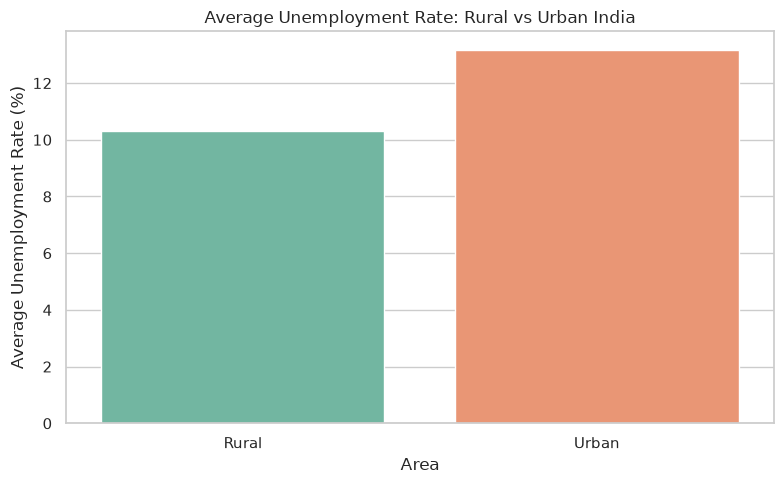

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=area_unemployment,
    x="Area",
    y="Average Unemployment Rate (%)",
    hue="Area",
    palette="Set2",
    legend=False
)

plt.title("Average Unemployment Rate: Rural vs Urban India")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()

plt.savefig(
    "../screenshots/rural_vs_urban_unemployment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
### Observations — Rural vs Urban

The chart compares average unemployment rates in rural
and urban areas.

The results show differences in unemployment between
the two area categories during the dataset period.

These averages are based on available observations and
are not population-weighted estimates.

SyntaxError: invalid syntax (397874313.py, line 3)

In [39]:
## 9. Key Findings and Conclusion

### Key Findings

1. Unemployment rates varied considerably across Indian states.
2. The monthly analysis showed a significant increase in average unemployment during April and May 2020.
3. The three-state comparison highlighted differences in unemployment trends across Maharashtra, Tamil Nadu and Haryana.
4. The correlation heatmap illustrated relationships between unemployment, employment and labour participation.
5. The pre-COVID and initial COVID-period comparison helped examine changes in unemployment during the early pandemic.
6. Rural and urban unemployment averages showed differences across area categories.

### Conclusion

This project analysed unemployment trends in India using
Python, Pandas, NumPy, Matplotlib and Seaborn.

Two datasets were cleaned and explored to understand
state-wise unemployment, monthly trends, employment
relationships and rural-urban differences.

The visualizations helped identify regional variations
and changes in unemployment during the initial COVID-19
period.

This analysis is descriptive and is based on the available
dataset observations. The calculated averages should not
be interpreted as official population-weighted national
unemployment estimates.

SyntaxError: invalid syntax (2862293504.py, line 5)

In [40]:
print("========== TASK 2 FINAL SUMMARY ==========")

print("\n1. DATASET A")
print("Records:", len(df_rural_clean))
print("Date range:", df_rural_clean["Date"].min(),
      "to", df_rural_clean["Date"].max())

print("\n2. DATASET B")
print("Records:", len(df_state_clean))
print("Regions:", df_state_clean["Region"].nunique())

print("\n3. TOP 5 STATES")
display(state_unemployment.head(5).round(2))

print("\n4. MONTHLY UNEMPLOYMENT")
display(monthly_unemployment.round(2))

print("\n5. PRE-COVID VS COVID")
display(period_comparison.round(2))

print("\n6. RURAL VS URBAN")
display(area_unemployment.round(2))

print("\n7. CORRELATION MATRIX")
display(correlation_matrix.round(3))

========== TASK 2 FINAL SUMMARY ==========

1. DATASET A
Records: 740
Date range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00

2. DATASET B
Records: 267
Regions: 27

3. TOP 5 STATES


,Region,Average Unemployment Rate (%)
0,Haryana,27.48
1,Tripura,25.06
2,Jharkhand,19.54
3,Bihar,19.47
4,Delhi,18.41



4. MONTHLY UNEMPLOYMENT


/tmp/ipykernel_32249/693653629.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_unemployment.round(2))


,Date,Estimated Unemployment Rate (%)
0,2020-01-31,9.20
1,2020-02-29,9.27
2,2020-03-31,10.78
3,2020-04-30,22.24
4,2020-05-31,23.24
5,2020-06-30,10.91
6,2020-07-31,9.83
7,2020-08-31,10.31
8,2020-09-30,8.71
9,2020-10-31,8.03



5. PRE-COVID VS COVID


,Period,Average Unemployment Rate (%)
0,Pre-COVID,9.51
1,COVID Onset,17.77



6. RURAL VS URBAN


,Area,Average Unemployment Rate (%)
0,Rural,10.32
1,Urban,13.17



7. CORRELATION MATRIX


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.00,-0.24,-0.07
Estimated Employed,-0.24,1.00,-0.05
Estimated Labour Participation Rate (%),-0.07,-0.05,1.00


In [41]:
print("=" * 55)
print("TASK 2 — FINAL VALIDATION")
print("=" * 55)

print("\nDATASET A")
print("Shape:", df_rural_clean.shape)
print("Missing values:", df_rural_clean.isnull().sum().sum())
print("Duplicates:", df_rural_clean.duplicated().sum())
print("Regions:", df_rural_clean["Region"].nunique())

print("\nDATASET B")
print("Shape:", df_state_clean.shape)
print("Missing values:", df_state_clean.isnull().sum().sum())
print("Duplicates:", df_state_clean.duplicated().sum())
print("Regions:", df_state_clean["Region"].nunique())

print("\nSCREENSHOT FILES")
for file in sorted(Path("../screenshots").glob("*.png")):
    print(file.name, "-", round(file.stat().st_size / 1024, 1), "KB")

TASK 2 — FINAL VALIDATION

DATASET A
Shape: (740, 7)
Missing values: 0
Duplicates: 0
Regions: 28

DATASET B
Shape: (267, 9)
Missing values: 0
Duplicates: 0
Regions: 27

SCREENSHOT FILES
monthly_unemployment_trend.png - 217.4 KB
pre_covid_vs_covid_comparison.png - 105.1 KB
rural_vs_urban_unemployment.png - 78.2 KB
statewise_unemployment_trends.png - 343.1 KB
top_10_unemployment_states.png - 138.2 KB
unemployment_correlation_heatmap.png - 163.9 KB
